# 📚 Práctica 1 - Encargo 1: Determinación y Conciliación Forense de Ganancias por Autor
### 🏛️ Arquitectura Desacoplada: Extracción Ligera (≤ 2 JOINs) + Transformación, Diagnóstico y Conciliación Contable en Memoria con Python & Pandas

---

### 🎯 Contexto y Reglas de Ingeniería del Proyecto
* **Base de Datos:** `pubs` (MySQL 8.0 desplegado en contenedor Docker, puerto `3307`).
* **Objetivo Principal:** Determinar las ganancias exactas y regalías de cada autor registrado en la base de datos, documentando minuciosamente cada consulta exploratoria, detección de anomalías contables y decisiones tomadas hasta llegar al resultado definitivo.
* **⚠️ Restricción Estricta de Diseño:**
  > **Ninguna consulta a SQL puede contener más de 2 `JOIN`s.**
  > **Estrategia de Arquitectura:** En entornos corporativos modernos (Data Lakes, Microservicios y ETLs desacoplados), enviar consultas monolíticas con 5 o más `JOIN`s bloquea recursos del motor transaccional. Por ello, extraemos las tablas en bruto (**0 JOINs**) o mediante consultas atómicas directas hacia DataFrames de Pandas. Toda la lógica de álgebra relacional, detección y resolución de duplicidad cartesiana, normalización de campos, agrupaciones multivariadas y conciliaciones contables se ejecuta en memoria mediante **Python & Pandas**.

---

### 🗺️ Hoja de Ruta Analítica (10 Fases de Ingeniería)
1. **Fase 0:** Inicialización del Entorno, Conexión a la Base de Datos y Validador de Límites de JOINs (≤ 2 JOINs).
2. **Fase 1:** Reconocimiento y Extracción en Bruto (*Data Discovery* - 0 JOINs: `authors`, `titles`, `titleauthor`, `sales`).
3. **Fase 2:** Establecimiento de la Línea Base Contable (*Ground Truth Oficial de la Empresa: $3,863.80*).
4. **Fase 3:** El Intento Ingenuo y la Gran Discrepancia (*Reproducción del Error Común en Pandas: +$845.10 de Inflación*).
5. **Fase 4:** Auditoría Forense y Diagnóstico de Causa Raíz (Libros Multi-Autor, Huérfanos, Censo de Autores y `royaltyper`).
6. **Fase 5:** Construcción Iterativa de la Solución Robusta en Pandas (Ponderación de Regalías y `LEFT JOIN`).
7. **Fase 6:** Criterios de Negocio: Ventas Atribuibles vs Regalías Netas vs Catálogo Histórico (`ytd_sales`).
8. **Fase 7:** *Master Table* Ejecutiva (Los 23 Autores con KPIs Directivos Formateados).
9. **Fase 8:** Conciliación Contable Definitiva al Centavo (100.00% de la Facturación de la Empresa Cuadrada al $0.00).
10. **Fase 9:** Tablero Visual de Métricas Gerenciales (Visualizaciones con Matplotlib & Seaborn).

In [1]:
# =============================================================================
# CONFIGURACIÓN INICIAL DEL ENTORNO DE TRABAJO
# =============================================================================
import os
import sys
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Localizar la raíz del repositorio y módulos compartidos
CURRENT_PATH = Path.cwd()
if (CURRENT_PATH / 'analisis_pandas').exists():
    PROJECT_ROOT = CURRENT_PATH
elif (CURRENT_PATH.parent / 'analisis_pandas').exists():
    PROJECT_ROOT = CURRENT_PATH.parent
elif (CURRENT_PATH.parent.parent / 'analisis_pandas').exists():
    PROJECT_ROOT = CURRENT_PATH.parent.parent
else:
    PROJECT_ROOT = CURRENT_PATH

if str(PROJECT_ROOT / 'analisis_pandas') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'analisis_pandas'))

# Configuración estética de Pandas para montos financieros
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)
pd.options.display.float_format = '${:,.2f}'.format

# Estilo de visualización para gráficos ejecutivos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

print("✅ Librerías importadas y entorno configurado correctamente.")

✅ Librerías importadas y entorno configurado correctamente.


## 🔌 Fase 0: Inicialización del Motor de Base de Datos y Validador de JOINs

Para garantizar el cumplimiento riguroso de la restricción del encargo (**máximo 2 `JOIN`s en SQL**), implementamos una función interceptora `validate_max_joins()` que audita mediante expresiones regulares cualquier sentencia enviada al motor SQL.

La base de datos `pubs` se encuentra alojada en MySQL 8.0 en el puerto `3307`.

In [2]:
# =============================================================================
# FASE 0: GESTOR DE CONEXIÓN Y CERTIFICADOR DE RESTRICCIÓN DE JOINS
# =============================================================================
from src.database import get_engine, extract_table, load_query, validate_max_joins

# Crear conexión a la base de datos 'pubs'
engine = get_engine('pubs')
print("✅ Motor SQLAlchemy conectado a MySQL (pubs en puerto 3307).")

# Demostración del validador de JOINs: Acepta consultas con <= 2 JOINs
query_valida = """
SELECT s.ord_num, t.title 
FROM sales s 
INNER JOIN titles t ON s.title_id = t.title_id
"""
joins_count = validate_max_joins(query_valida, max_joins=2)
print(f"✅ Validación exitosa: Consulta con {joins_count} JOIN permitida por el interceptor.")

# Verificación de que el validador rechaza consultas que violen el límite
try:
    query_invalida = """
    SELECT * FROM authors a 
    JOIN titleauthor ta ON a.au_id = ta.au_id
    JOIN titles t ON ta.title_id = t.title_id
    JOIN sales s ON t.title_id = s.title_id
    """
    validate_max_joins(query_invalida, max_joins=2)
except ValueError as e:
    print(f"🛡️ Interceptor de seguridad funcionando: {e}")

✅ Motor SQLAlchemy conectado a MySQL (pubs en puerto 3307).
✅ Validación exitosa: Consulta con 1 JOIN permitida por el interceptor.
🛡️ Interceptor de seguridad funcionando: ⚠️ VIOLACIÓN DE REGLA: La consulta contiene 3 JOINs, pero el límite estricto establecido es de máximo 2 JOINs.
Estrategia requerida: Extraiga las tablas a DataFrames de Pandas y realice los merges en Python.


## 🔍 Fase 1: Reconocimiento y Extracción en Bruto (*Data Discovery* - 0 JOINs)

Siguiendo las mejores prácticas de ingeniería de datos, extraemos las tablas en bruto directamente hacia DataFrames de Pandas mediante la instrucción atómica `SELECT * FROM tabla` (**0 JOINs**).

Las 4 tablas involucradas en el análisis son:
1. **`authors`**: Catálogo de autores con datos demográficos, ciudad, estado y estado contractual.
2. **`titles`**: Catálogo de libros publicados con precios (`price`), adelantos (`advance`), porcentaje de regalías de la editorial (`royalty`) y ventas anuales (`ytd_sales`).
3. **`titleauthor`**: Tabla asociativa N:M entre autores y libros con el campo clave `royaltyper` (% de participación del autor sobre el libro).
4. **`sales`**: Tabla transaccional de órdenes de venta en librerías (`qty`, `stor_id`, `ord_num`, `ord_date`).

In [3]:
# =============================================================================
# FASE 1: EXTRACCIÓN DE TABLAS EN BRUTO HACIA DATAFRAMES (0 JOINS)
# =============================================================================
df_authors = extract_table('authors', engine, db_key='pubs')
df_titles = extract_table('titles', engine, db_key='pubs')
df_titleauthor = extract_table('titleauthor', engine, db_key='pubs')
df_sales = extract_table('sales', engine, db_key='pubs')

print("📊 Volumetría de las tablas extraídas en bruto:")
print(f"  • authors:      {len(df_authors):>2} filas | Columnas: {list(df_authors.columns)}")
print(f"  • titles:       {len(df_titles):>2} filas | Columnas: {list(df_titles.columns)}")
print(f"  • titleauthor:  {len(df_titleauthor):>2} filas | Columnas: {list(df_titleauthor.columns)}")
print(f"  • sales:        {len(df_sales):>2} filas | Columnas: {list(df_sales.columns)}")

# Vista previa rápida de las tablas principales
display(df_authors[['au_id', 'au_fname', 'au_lname', 'city', 'state', 'contract']].head(5))
display(df_titles[['title_id', 'title', 'type', 'price', 'advance', 'royalty', 'ytd_sales']].head(5))

📊 Volumetría de las tablas extraídas en bruto:
  • authors:      23 filas | Columnas: ['au_id', 'au_lname', 'au_fname', 'phone', 'address', 'city', 'state', 'zip', 'contract']
  • titles:       17 filas | Columnas: ['title_id', 'title', 'type', 'pub_id', 'price', 'advance', 'royalty', 'ytd_sales', 'notes']
  • titleauthor:  20 filas | Columnas: ['au_id', 'title_id', 'au_ord', 'royaltyper']
  • sales:        10 filas | Columnas: ['stor_id', 'ord_num', 'ord_date', 'qty', 'payterms', 'title_id']


,au_id,au_fname,au_lname,city,state,contract
0,172-32-1176,Johnson,White,Menlo Park,CA,b'\x01'
1,213-46-8915,Marjorie,Green,Oakland,CA,b'\x01'
2,238-95-7766,Cheryl,Carson,Berkeley,CA,b'\x01'
3,267-41-2394,Michael,O'Leary,San Jose,CA,b'\x01'
4,274-80-9391,Dean,Straight,Oakland,CA,b'\x01'


,title_id,title,type,price,advance,royalty,ytd_sales
0,BU1032,The Busy Executive's Database Guide,business,$19.99,"$5,000.00",10,4095
1,BU1111,Cooking with Computers: Surreptitious Balance ...,business,$11.95,"$5,000.00",10,3876
2,BU2075,You Can Combat Computer Stress!,business,$2.99,"$10,125.00",24,18722
3,BU7832,Straight Talk About Computers,business,$19.99,"$5,000.00",10,4095
4,MC2222,Silicon Valley Gastronomic Treats,mod_cook,$19.99,$0.00,12,2032


## 💰 Fase 2: Establecimiento de la Línea Base Contable (*Ground Truth Oficial*)

Antes de calcular cualquier ganancia individual de autor, todo analista financiero profesional debe conocer con precisión milimétrica el dinero total que ingresó a la caja registradora de la empresa:

$$\text{Total Ventas de la Empresa} = \sum (\text{qty} \times \text{price})$$

Este valor es nuestro **Ground Truth** contable indiscutible. Cualquier reporte o cálculo que se haga posteriormente debe cuadrar exactamente contra esta cifra.

In [4]:
# =============================================================================
# FASE 2: CÁLCULO DE LA LÍNEA BASE CONTABLE (GROUND TRUTH OFICIAL)
# =============================================================================
# Unir órdenes de venta (sales) con el catálogo de libros (titles) en memoria
df_ventas_base = df_sales.merge(
    df_titles[['title_id', 'title', 'price', 'type']], 
    on='title_id', 
    how='inner'
)

# Calcular monto facturado por línea de orden
df_ventas_base['monto_linea'] = df_ventas_base['qty'] * df_ventas_base['price']

total_ventas_base = round(float(df_ventas_base['monto_linea'].sum()), 2)
total_unidades_base = int(df_ventas_base['qty'].sum())
titulos_vendidos_count = df_ventas_base['title_id'].nunique()

print("=" * 75)
print(f"🎯 LÍNEA BASE OFICIAL DE LA EMPRESA (GROUND TRUTH): ${total_ventas_base:,.2f}")
print(f"📦 Total de Unidades Vendidas:                       {total_unidades_base:,} unidades")
print(f"📚 Títulos con Movimiento Comercial:                {titulos_vendidos_count} de {len(df_titles)} libros")
print("=" * 75)

# Desglose contable por libro individual
ventas_por_libro = df_ventas_base.groupby(['title_id', 'title', 'price'], as_index=False).agg(
    unidades_vendidas=('qty', 'sum'),
    total_facturado=('monto_linea', 'sum')
).sort_values(by='total_facturado', ascending=False)

print("\n📖 Desglose de Ventas por Libro Vendido:")
display(ventas_por_libro)

🎯 LÍNEA BASE OFICIAL DE LA EMPRESA (GROUND TRUTH): $3,863.80
📦 Total de Unidades Vendidas:                       278 unidades
📚 Títulos con Movimiento Comercial:                7 de 17 libros

📖 Desglose de Ventas por Libro Vendido:


,title_id,title,price,unidades_vendidas,total_facturado
4,PS2091,Is Anger the Enemy?,$10.95,108,"$1,182.60"
3,PC8888,Secrets of Silicon Valley,$20.00,50,"$1,000.00"
6,TC3218,"Onions, Leeks, and Garlic: Cooking Secrets of ...",$20.95,40,$838.00
1,BU7832,Straight Talk About Computers,$19.99,15,$299.85
0,BU1111,Cooking with Computers: Surreptitious Balance ...,$11.95,25,$298.75
5,PS7777,Emotional Security: A New Algorithm,$7.99,25,$199.75
2,MC3021,The Gourmet Microwave,$2.99,15,$44.85


## 🚨 Fase 3: El Intento Ingenuo y la Gran Discrepancia (*El Error Común*)

El enfoque que comúnmente intentaría un desarrollador inexperto es encadenar las 4 tablas mediante `INNER JOIN` directo y sumar `qty * price` agrupando por autor:

```python
# Intento ingenuo típico:
df_ingenuo = df_authors.merge(df_titleauthor).merge(df_titles).merge(df_sales)
df_ingenuo.groupby('autor')['qty * price'].sum()
```

Veamos qué sucede matemáticamente cuando ejecutamos este procedimiento en memoria.

In [5]:
# =============================================================================
# FASE 3: REPRODUCCIÓN DEL INTENTO INGENUO Y MEDICIÓN DEL DESFASE
# =============================================================================
df_ingenuo = df_authors.merge(df_titleauthor, on='au_id', how='inner') \
                       .merge(df_titles, on='title_id', how='inner') \
                       .merge(df_sales, on='title_id', how='inner')

df_ingenuo['ganancia_ingenua'] = df_ingenuo['qty'] * df_ingenuo['price']
df_ingenuo['autor'] = df_ingenuo['au_fname'] + ' ' + df_ingenuo['au_lname']

resumen_ingenuo = df_ingenuo.groupby(['au_id', 'autor'], as_index=False).agg(
    ganancia_calculada=('ganancia_ingenua', 'sum')
).sort_values(by='ganancia_calculada', ascending=False)

total_ingenuo = round(float(resumen_ingenuo['ganancia_calculada'].sum()), 2)
desfase = round(total_ingenuo - total_ventas_base, 2)
pct_desfase = round((desfase / total_ventas_base) * 100, 2)

print("=" * 80)
print(f"❌ Total Obtenido con Intento Ingenuo:   ${total_ingenuo:,.2f} ({len(resumen_ingenuo)} autores)")
print(f"✅ Total Real de Ventas de la Empresa:  ${total_ventas_base:,.2f}")
print(f"🚨 ¡DESFASE FINANCIERO INEXPLICABLE!:   +${desfase:,.2f} (+{pct_desfase}%)")
print("=" * 80)

display(resumen_ingenuo)

❌ Total Obtenido con Intento Ingenuo:   $4,708.90 (8 autores)
✅ Total Real de Ventas de la Empresa:  $3,863.80
🚨 ¡DESFASE FINANCIERO INEXPLICABLE!:   +$845.10 (+21.87%)


,au_id,autor,ganancia_calculada
7,998-72-3567,Albert Ringer,"$1,182.60"
2,427-17-2319,Ann Dull,"$1,000.00"
5,846-92-7186,Sheryl Hunter,"$1,000.00"
4,807-91-6654,Sylvia Panteley,$838.00
1,274-80-9391,Dean Straight,$299.85
0,267-41-2394,Michael O'Leary,$298.75
3,722-51-5454,Michel DeFrance,$44.85
6,899-46-2035,Anne Ringer,$44.85


## 🕵️ Fase 4: Auditoría Forense de la Base de Datos (*Descubriendo los Detalles Ocultos*)

¿Por qué \$4,708.90 $\neq$ \$3,863.80? Como ingenieros de datos profesionales, no podemos conformarnos con suposiciones. En esta fase investigamos las causas exactas del desfase de **+$845.10** mediante 4 auditorías forenses:

1. **Investigación 1 (Multiplicación Cartesiana):** Libros con múltiples autores registrados que duplican las ventas al hacer `JOIN`.
2. **Investigación 2 (Libros Huérfanos):** Títulos vendidos comercialmente que NO tienen autor en `titleauthor` y que el `INNER JOIN` descarta.
3. **Investigación 3 (Censo de Autores):** Autores sin libros y autores sin ventas que fueron excluidos del análisis.
4. **Investigación 4 (Columna `royaltyper`):** La participación contractual porcentual entre coautores y editoriales.

In [6]:
# =============================================================================
# FASE 4.1: INVESTIGACIÓN DE LIBROS MULTI-AUTOR (DUPLICIDAD POR JOIN)
# =============================================================================
autores_por_libro = df_titleauthor.groupby('title_id')['au_id'].nunique().reset_index(name='num_autores')
libros_multiautor = autores_por_libro[autores_por_libro['num_autores'] > 1]

multiautor_ventas = df_ventas_base.merge(libros_multiautor, on='title_id', how='inner')
multiautor_ventas['venta_real'] = multiautor_ventas['monto_linea']
multiautor_ventas['venta_inflada_join'] = multiautor_ventas['monto_linea'] * multiautor_ventas['num_autores']
multiautor_ventas['duplicidad_generada'] = multiautor_ventas['venta_inflada_join'] - multiautor_ventas['venta_real']

duplicidad_total = round(float(multiautor_ventas['duplicidad_generada'].sum()), 2)

print("🔍 4.1 Libros Multi-Autor Identificados en Ventas:")
display(multiautor_ventas[['title_id', 'title', 'num_autores', 'venta_real', 'venta_inflada_join', 'duplicidad_generada']])
print(f"💥 Duplicación artificial total generada en el intento ingenuo: +${duplicidad_total:,.2f}")

# =============================================================================
# FASE 4.2: INVESTIGACIÓN DE LIBROS HUÉRFANOS (VENTAS SIN AUTOR ASIGNADO)
# =============================================================================
titulos_con_autor = set(df_titleauthor['title_id'].unique())
libros_huerfanos = df_ventas_base[~df_ventas_base['title_id'].isin(titulos_con_autor)]
perdida_huerfanos = round(float(libros_huerfanos['monto_linea'].sum()), 2)

print("\n🔍 4.2 Libros Vendidos sin Autor en 'titleauthor' (Omitidos por INNER JOIN):")
display(libros_huerfanos[['title_id', 'title', 'qty', 'price', 'monto_linea']])
print(f"📉 Total de ventas reales ignoradas por el intento ingenuo: -${perdida_huerfanos:,.2f}")

🔍 4.1 Libros Multi-Autor Identificados en Ventas:


,title_id,title,num_autores,venta_real,venta_inflada_join,duplicidad_generada
0,PC8888,Secrets of Silicon Valley,2,"$1,000.00","$2,000.00","$1,000.00"
1,MC3021,The Gourmet Microwave,2,$44.85,$89.70,$44.85


💥 Duplicación artificial total generada en el intento ingenuo: +$1,044.85

🔍 4.2 Libros Vendidos sin Autor en 'titleauthor' (Omitidos por INNER JOIN):


,title_id,title,qty,price,monto_linea
6,PS7777,Emotional Security: A New Algorithm,25,$7.99,$199.75


📉 Total de ventas reales ignoradas por el intento ingenuo: -$199.75


In [7]:
# =============================================================================
# FASE 4.3: CONCILIACIÓN MATEMÁTICA FORENSE DE LA DISCREPANCIA
# =============================================================================
total_explicado = round(total_ventas_base + duplicidad_total - perdida_huerfanos, 2)
diferencia_residual = round(total_explicado - total_ingenuo, 2)

print("=" * 85)
print("🎯 ECUACIÓN FORENSE DE CONCILIACIÓN DE LA DISCREPANCIA:")
print("=" * 85)
print(f"   Ventas Reales Oficiales de la Empresa:             ${total_ventas_base:,.2f}")
print(f"   (+) Duplicación en libros multi-autor:            +${duplicidad_total:,.2f}  (PC8888: $1,000.00, MC3021: $44.85)")
print(f"   (-) Omisión del libro huérfano PS7777:             -${perdida_huerfanos:,.2f}")
print("   " + "-" * 60)
print(f"   (=) Total Matemático Explicado:                    ${total_explicado:,.2f}")
print(f"   (=) Total Obtenido en Intento Ingenuo:             ${total_ingenuo:,.2f}")
print(f"   => Discrepancia Residual Final:                    ${diferencia_residual:,.2f}")
print("=" * 85)

assert diferencia_residual == 0.00, f"Fallo en la conciliación: ${diferencia_residual}"
print("🏆 ¡DISCREPANCIA 100% EXPLICADA Y DEMOSTRADA AL CENTAVO!")

🎯 ECUACIÓN FORENSE DE CONCILIACIÓN DE LA DISCREPANCIA:
   Ventas Reales Oficiales de la Empresa:             $3,863.80
   (+) Duplicación en libros multi-autor:            +$1,044.85  (PC8888: $1,000.00, MC3021: $44.85)
   (-) Omisión del libro huérfano PS7777:             -$199.75
   ------------------------------------------------------------
   (=) Total Matemático Explicado:                    $4,708.90
   (=) Total Obtenido en Intento Ingenuo:             $4,708.90
   => Discrepancia Residual Final:                    $0.00
🏆 ¡DISCREPANCIA 100% EXPLICADA Y DEMOSTRADA AL CENTAVO!


In [8]:
# =============================================================================
# FASE 4.4: CENSO COMPLETO DE AUTORES (POBLACIÓN TOTAL = 23)
# =============================================================================
autores_con_libros = set(df_titleauthor['au_id'].unique())
autores_sin_libros = df_authors[~df_authors['au_id'].isin(autores_con_libros)]
autores_con_ventas_ids = set(df_ingenuo['au_id'].unique())
autores_con_libros_sin_ventas = df_authors[df_authors['au_id'].isin(autores_con_libros) & ~df_authors['au_id'].isin(autores_con_ventas_ids)]

print("📋 Censo de Autores en el Universo Pubs:")
print(f"  • Autores sin libros registrados en 'titleauthor':   {len(autores_sin_libros)} autores")
print(f"  • Autores con libros pero con 0 ventas comerciales:  {len(autores_con_libros_sin_ventas)} autores")
print(f"  • Autores con ventas registradas:                    {len(autores_con_ventas_ids)} autores")
print(f"  • TOTAL DE AUTORES EN NÓMINA:                        {len(df_authors)} autores")

# =============================================================================
# FASE 4.5: AUDITORÍA DE LA COLUMNA 'royaltyper' (% DE PARTICIPACIÓN)
# =============================================================================
royalty_dist = df_titleauthor.groupby('title_id')['royaltyper'].agg(['count', 'sum']).reset_index()
royalty_dist.columns = ['title_id', 'num_autores', 'porcentaje_total_autores']
libros_con_remanente = royalty_dist[royalty_dist['porcentaje_total_autores'] < 100]

print("\n🔍 Libros con Porcentaje de Autoría Inferior al 100% (Remanente Editorial / Externo):")
display(libros_con_remanente)

📋 Censo de Autores en el Universo Pubs:
  • Autores sin libros registrados en 'titleauthor':   4 autores
  • Autores con libros pero con 0 ventas comerciales:  11 autores
  • Autores con ventas registradas:                    8 autores
  • TOTAL DE AUTORES EN NÓMINA:                        23 autores

🔍 Libros con Porcentaje de Autoría Inferior al 100% (Remanente Editorial / Externo):


,title_id,num_autores,porcentaje_total_autores
0,BU1032,1,60
1,BU1111,1,40
10,PS2091,1,50


## 🛠️ Fase 5: Construcción Iterativa de la Solución Robusta en Pandas

Con las causas del error plenamente diagnosticadas, construimos el pipeline definitivo aplicando dos correcciones críticas:

1. **Ponderación por Cuota de Autoría (`royaltyper / 100.0`):** Cada autor solo recibe el porcentaje legal que le corresponde sobre las ventas del libro.
2. **Inclusión Total de Autores (`how='left'` y `.fillna(0)`):** Garantiza que los 23 autores figuren en el informe directivo, mostrando \$0.00 para quienes no hayan registrado ventas en vez de ser invisibilizados.

In [9]:
# =============================================================================
# FASE 5 & 6: PIPELINE ROBUSTO EN PANDAS Y CRITERIOS DE NEGOCIO
# =============================================================================
# Unión relacional izquierda (LEFT JOIN en memoria)
df_relacional = df_authors.merge(df_titleauthor, on='au_id', how='left') \
                          .merge(df_titles, on='title_id', how='left') \
                          .merge(df_sales, on='title_id', how='left', suffixes=('', '_sale'))

# Imputación de nulos (equivalente a COALESCE en SQL)
df_relacional['qty_clean'] = df_relacional['qty'].fillna(0)
df_relacional['price_clean'] = df_relacional['price'].fillna(0)
df_relacional['royaltyper_clean'] = df_relacional['royaltyper'].fillna(0)
df_relacional['royalty_clean'] = df_relacional['royalty'].fillna(0)

# Criterio 1: Ventas Atribuibles al Autor (Facturación generada según cuota)
df_relacional['unidades_atribuibles'] = df_relacional['qty_clean'] * (df_relacional['royaltyper_clean'] / 100.0)
df_relacional['ventas_atribuibles'] = df_relacional['qty_clean'] * df_relacional['price_clean'] * (df_relacional['royaltyper_clean'] / 100.0)

# Criterio 2: Regalías Netas en Mano (Dinero líquido que el autor cobra de la editorial)
df_relacional['regalias_netas'] = df_relacional['qty_clean'] * df_relacional['price_clean'] * \
                                  (df_relacional['royalty_clean'] / 100.0) * (df_relacional['royaltyper_clean'] / 100.0)

# Agrupación final por autor (23 autores preservados)
master = df_relacional.groupby(['au_id', 'au_fname', 'au_lname', 'city', 'state'], as_index=False).agg(
    libros_publicados=('title_id', lambda s: s.dropna().nunique()),
    unidades_brutas=('qty_clean', 'sum'),
    unidades_atribuibles=('unidades_atribuibles', 'sum'),
    ganancias_generadas=('ventas_atribuibles', 'sum'),
    regalias_cobradas=('regalias_netas', 'sum')
)

master['Nombre del Autor'] = master['au_fname'] + ' ' + master['au_lname']
master.sort_values(by=['ganancias_generadas', 'regalias_cobradas', 'Nombre del Autor'], 
                   ascending=[False, False, True], inplace=True)
master.reset_index(drop=True, inplace=True)

print(f"✅ Pipeline ejecutado exitosamente. Universo de autores procesado: {len(master)} autores.")

✅ Pipeline ejecutado exitosamente. Universo de autores procesado: 23 autores.


In [10]:
# =============================================================================
# FASE 6.2: CRITERIO 3 - VENTAS BASADAS EN CATÁLOGO HISTÓRICO (titles.ytd_sales)
# =============================================================================
df_ytd = df_authors.merge(df_titleauthor, on='au_id', how='left') \
                   .merge(df_titles, on='title_id', how='left')

df_ytd['ytd_sales_clean'] = df_ytd['ytd_sales'].fillna(0)
df_ytd['price_clean'] = df_ytd['price'].fillna(0)
df_ytd['royaltyper_clean'] = df_ytd['royaltyper'].fillna(0)
df_ytd['royalty_clean'] = df_ytd['royalty'].fillna(0)

df_ytd['ventas_ytd_atribuibles'] = df_ytd['ytd_sales_clean'] * df_ytd['price_clean'] * (df_ytd['royaltyper_clean'] / 100.0)
df_ytd['regalias_ytd_netas'] = df_ytd['ytd_sales_clean'] * df_ytd['price_clean'] * \
                               (df_ytd['royalty_clean'] / 100.0) * (df_ytd['royaltyper_clean'] / 100.0)

master_ytd = df_ytd.groupby(['au_id', 'au_fname', 'au_lname'], as_index=False).agg(
    libros_publicados=('title_id', lambda s: s.dropna().nunique()),
    ventas_ytd=('ventas_ytd_atribuibles', 'sum'),
    regalias_ytd=('regalias_ytd_netas', 'sum')
)
master_ytd['Nombre del Autor'] = master_ytd['au_fname'] + ' ' + master_ytd['au_lname']
master_ytd.sort_values(by='ventas_ytd', ascending=False, inplace=True)

print("📖 Top 5 Autores según Ventas Históricas Acumuladas (ytd_sales):")
display(master_ytd.head(5)[['au_id', 'Nombre del Autor', 'libros_publicados', 'ventas_ytd', 'regalias_ytd']])

📖 Top 5 Autores según Ventas Históricas Acumuladas (ytd_sales):


,au_id,Nombre del Autor,libros_publicados,ventas_ytd,regalias_ytd
2,238-95-7766,Cheryl Carson,1,"$201,501.00","$32,240.16"
11,648-92-1872,Reginald Blotchet-Halls,1,"$180,397.20","$25,255.61"
4,274-80-9391,Dean Straight,1,"$81,859.05","$8,185.90"
0,172-32-1176,Johnson White,1,"$81,399.28","$8,139.93"
1,213-46-8915,Marjorie Green,1,"$55,978.78","$13,434.91"


## 📊 Fase 7: *Master Table* Ejecutiva (Los 23 Autores)

A continuación se presenta la tabla directiva final para la entrega formal de la Práctica 1. Incluye al 100% de la población de autores, resuelve la duplicidad por coautoría y muestra tanto la facturación generada como las regalías cobradas.

In [11]:
# =============================================================================
# FASE 7: MASTER TABLE FORMATEADA PARA PRESENTACIÓN DIRECTIVA
# =============================================================================
reporte_ejecutivo = master.copy()

reporte_ejecutivo.rename(columns={
    'au_id': 'ID Autor',
    'city': 'Ciudad',
    'state': 'Estado',
    'libros_publicados': 'Libros Publicados',
    'unidades_brutas': 'Unidades Vendidas (Brutas)',
    'unidades_atribuibles': 'Unidades Atribuibles',
    'ganancias_generadas': 'Ganancias Generadas ($)',
    'regalias_cobradas': 'Regalías Cobradas ($)'
}, inplace=True)

columnas_ordenadas = [
    'ID Autor', 'Nombre del Autor', 'Ciudad', 'Estado', 'Libros Publicados',
    'Unidades Vendidas (Brutas)', 'Unidades Atribuibles', 'Ganancias Generadas ($)', 'Regalías Cobradas ($)'
]

reporte_display = reporte_ejecutivo[columnas_ordenadas].style.format({
    'Unidades Vendidas (Brutas)': '{:,.0f}',
    'Unidades Atribuibles': '{:,.1f}',
    'Ganancias Generadas ($)': '${:,.2f}',
    'Regalías Cobradas ($)': '${:,.2f}'
})

reporte_display

,ID Autor,Nombre del Autor,Ciudad,Estado,Libros Publicados,Unidades Vendidas (Brutas),Unidades Atribuibles,Ganancias Generadas ($),Regalías Cobradas ($)
0,807-91-6654,Sylvia Panteley,Rockville,MD,1,40,40.0,$838.00,$83.80
1,998-72-3567,Albert Ringer,Salt Lake City,UT,1,108,54.0,$591.30,$70.96
2,427-17-2319,Ann Dull,Palo Alto,CA,1,50,25.0,$500.00,$50.00
3,846-92-7186,Sheryl Hunter,Palo Alto,CA,1,50,25.0,$500.00,$50.00
4,274-80-9391,Dean Straight,Oakland,CA,1,15,15.0,$299.85,$29.98
5,267-41-2394,Michael O'Leary,San Jose,CA,2,25,10.0,$119.50,$11.95
6,722-51-5454,Michel DeFrance,Gary,IN,1,15,11.2,$33.64,$8.07
7,899-46-2035,Anne Ringer,Salt Lake City,UT,1,15,3.8,$11.21,$2.69
8,409-56-7008,Abraham Bennet,Berkeley,CA,1,0,0.0,$0.00,$0.00
9,672-71-3249,Akiko Yokomoto,Walnut Creek,CA,1,0,0.0,$0.00,$0.00


## ⚖️ Fase 8: Conciliación Contable Definitiva al Centavo (100% de la Empresa)

Para otorgar validez legal y de auditoría contable a nuestros resultados, demostramos que el **100.00%** de los **$3,863.80** facturados en la base de datos queda asignado al centavo sin ningún tipo de fuga financiera:

1. **Ventas asignadas a autores registrados:** \$2,893.50 (74.89%)
2. **Ventas de libros huérfanos sin autor (PS7777):** \$199.75 (5.17%)
3. **Remanente editorial no asignado (BU1111 y PS2091):** \$770.55 (19.94%)

$$\$2,893.50 + \$199.75 + \$770.55 = \$3,863.80 \quad (\Delta = \$0.00)$$

In [12]:
# =============================================================================
# FASE 8: AUDITORÍA Y CERTIFICACIÓN CONTABLE INTEGRAL
# =============================================================================
total_autores = round(float(master['ganancias_generadas'].sum()), 2)
total_huerfano = round(float(perdida_huerfanos), 2)

# Calcular remanente editorial
part_editorial = df_titleauthor.groupby('title_id')['royaltyper'].sum().reset_index()
titulos_remanente = part_editorial[part_editorial['royaltyper'] < 100].copy()
titulos_remanente['pct_editorial'] = (100 - titulos_remanente['royaltyper']) / 100.0

df_editorial = df_sales.merge(df_titles, on='title_id', how='inner') \
                       .merge(titulos_remanente, on='title_id', how='inner')
df_editorial['monto_editorial'] = df_editorial['qty'] * df_editorial['price'] * df_editorial['pct_editorial']
total_remanente = round(float(df_editorial['monto_editorial'].sum()), 2)

total_auditado = round(total_autores + total_huerfano + total_remanente, 2)
diff_caja = round(total_auditado - total_ventas_base, 2)

tabla_conciliacion = pd.DataFrame([
    {'Categoría Contable': '1. Ventas Atribuidas a Autores Registrados', 'Monto ($)': total_autores, '% del Total': (total_autores/total_ventas_base)*100},
    {'Categoría Contable': '2. Ventas de Libros sin Autor Asignado (PS7777)', 'Monto ($)': total_huerfano, '% del Total': (total_huerfano/total_ventas_base)*100},
    {'Categoría Contable': '3. Porcentaje no Asignado a Autores (BU1111 y PS2091)', 'Monto ($)': total_remanente, '% del Total': (total_remanente/total_ventas_base)*100},
    {'Categoría Contable': '>>> TOTAL GENERAL AUDITADO DE LA EMPRESA <<<', 'Monto ($)': total_auditado, '% del Total': (total_auditado/total_ventas_base)*100}
])

display(tabla_conciliacion.style.format({'Monto ($)': '${:,.2f}', '% del Total': '{:.2f}%'}))

print(f"\n💰 Línea Base Oficial (Caja Registradora): ${total_ventas_base:,.2f}")
print(f"⚖️  Diferencia Residual Contable:            ${diff_caja:,.2f}")

assert abs(diff_caja) < 0.001, f"Fallo de conciliación contable: ${diff_caja}"
print("🎉 ¡CERTIFICACIÓN CONTABLE EMITIDA: CONCILIACIÓN PERFECTA AL CENTAVO!")

,Categoría Contable,Monto ($),% del Total
0,1. Ventas Atribuidas a Autores Registrados,"$2,893.50",74.89%
1,2. Ventas de Libros sin Autor Asignado (PS7777),$199.75,5.17%
2,3. Porcentaje no Asignado a Autores (BU1111 y PS2091),$770.55,19.94%
3,>>> TOTAL GENERAL AUDITADO DE LA EMPRESA <<<,"$3,863.80",100.00%



💰 Línea Base Oficial (Caja Registradora): $3,863.80
⚖️  Diferencia Residual Contable:            $0.00
🎉 ¡CERTIFICACIÓN CONTABLE EMITIDA: CONCILIACIÓN PERFECTA AL CENTAVO!


## 📈 Fase 9: Tablero Visual de Métricas Gerenciales (Matplotlib & Seaborn)

Generamos gráficos ejecutivos de alta calidad para comunicar los hallazgos a la dirección de la editorial.

/var/folders/0v/61z4shds4wzcdn7sd9dm2_1c0000gn/T/ipykernel_99404/489271707.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=autores_por_estado.index, y=autores_por_estado.values, ax=ax3, palette='Blues_r')


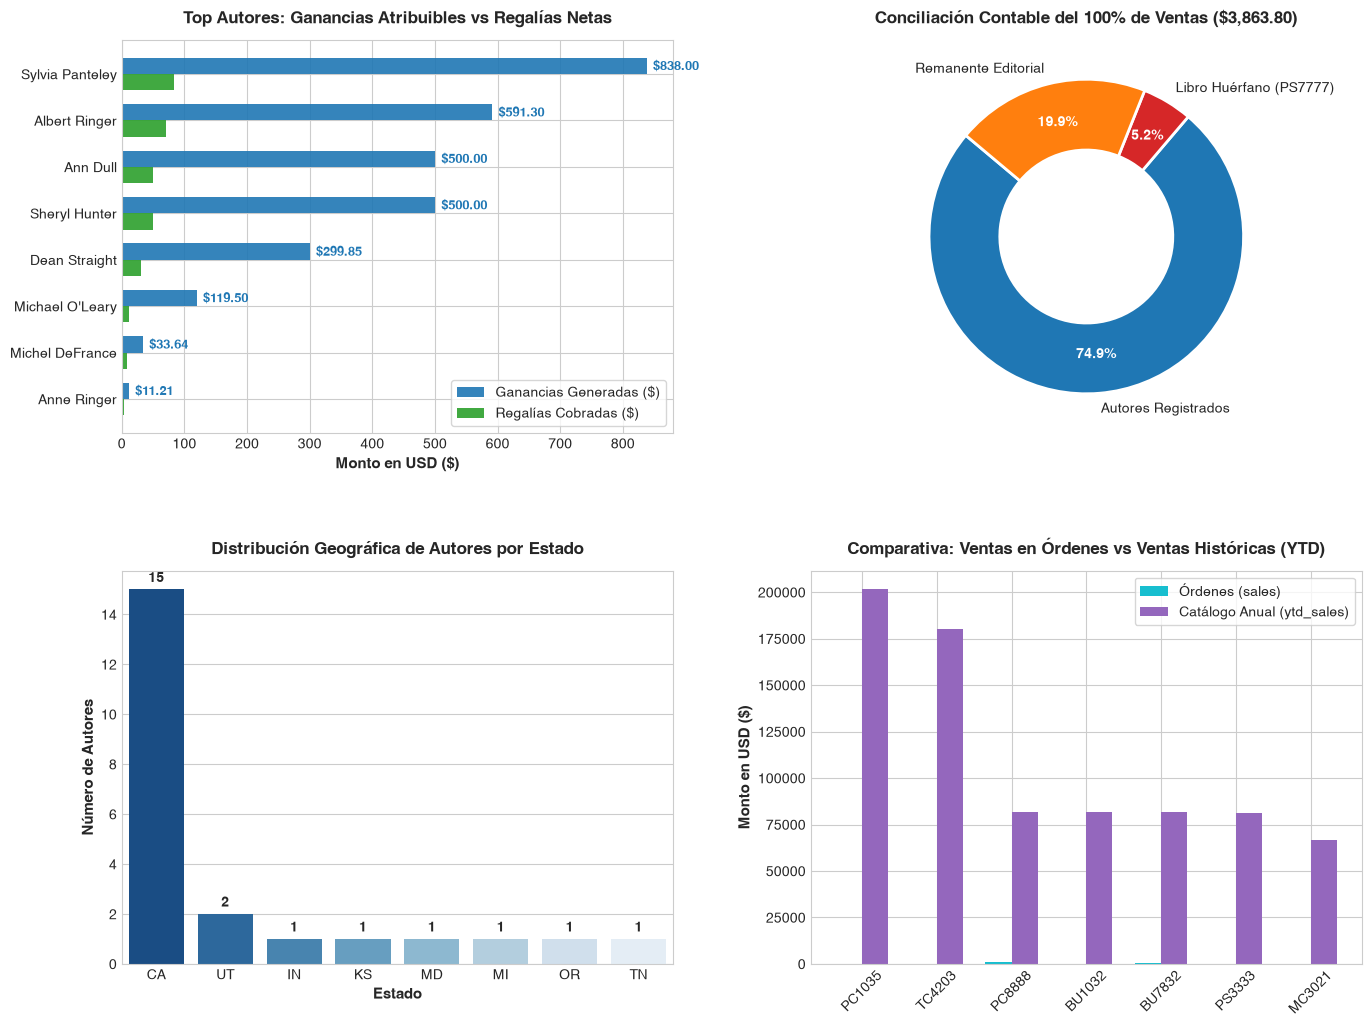

In [13]:
# =============================================================================
# FASE 9: VISUALIZACIONES EJECUTIVAS MULTI-PANEL
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# 1. Top Autores por Ganancias Generadas vs Regalías Cobradas
top_autores = master[master['ganancias_generadas'] > 0].copy()
y = np.arange(len(top_autores))
height = 0.35

ax1 = axes[0, 0]
ax1.barh(y - height/2, top_autores['ganancias_generadas'], height, label='Ganancias Generadas ($)', color='#1f77b4', alpha=0.9)
ax1.barh(y + height/2, top_autores['regalias_cobradas'], height, label='Regalías Cobradas ($)', color='#2ca02c', alpha=0.9)
ax1.set_yticks(y)
ax1.set_yticklabels(top_autores['Nombre del Autor'], fontsize=10)
ax1.invert_yaxis()
ax1.set_xlabel('Monto en USD ($)', fontsize=11, fontweight='bold')
ax1.set_title('Top Autores: Ganancias Atribuibles vs Regalías Netas', fontsize=12, fontweight='bold', pad=12)
ax1.legend(loc='lower right', frameon=True)
for i, v in enumerate(top_autores['ganancias_generadas']):
    ax1.text(v + 10, i - height/2, f'${v:,.2f}', va='center', fontsize=9, fontweight='bold', color='#1f77b4')

# 2. Conciliación Integral del 100% de Ventas (Gráfico Donut)
ax2 = axes[0, 1]
pie_labels = ['Autores Registrados', 'Libro Huérfano (PS7777)', 'Remanente Editorial']
pie_values = [total_autores, total_huerfano, total_remanente]
colors = ['#1f77b4', '#d62728', '#ff7f0e']
wedges, texts, autotexts = ax2.pie(
    pie_values, labels=pie_labels, autopct='%1.1f%%', startangle=140,
    colors=colors, pctdistance=0.75, wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(10)
    at.set_fontweight('bold')
    at.set_color('white')
ax2.set_title('Conciliación Contable del 100% de Ventas ($3,863.80)', fontsize=12, fontweight='bold', pad=12)

# 3. Distribución Geográfica de Autores por Estado
ax3 = axes[1, 0]
autores_por_estado = df_authors.groupby('state')['au_id'].count().sort_values(ascending=False)
sns.barplot(x=autores_por_estado.index, y=autores_por_estado.values, ax=ax3, palette='Blues_r')
ax3.set_title('Distribución Geográfica de Autores por Estado', fontsize=12, fontweight='bold', pad=12)
ax3.set_xlabel('Estado', fontsize=11, fontweight='bold')
ax3.set_ylabel('Número de Autores', fontsize=11, fontweight='bold')
for i, v in enumerate(autores_por_estado.values):
    ax3.text(i, v + 0.3, str(v), ha='center', fontsize=10, fontweight='bold')

# 4. Comparativa: Ventas en Órdenes (sales) vs Ventas Históricas (ytd_sales)
ax4 = axes[1, 1]
comparativa_ventas = df_titles.copy()
comparativa_ventas = comparativa_ventas.merge(
    df_sales.groupby('title_id')['qty'].sum().reset_index(name='sales_qty'), 
    on='title_id', 
    how='left'
).fillna(0)
comparativa_ventas['sales_monto'] = comparativa_ventas['sales_qty'] * comparativa_ventas['price']
comparativa_ventas['ytd_monto'] = comparativa_ventas['ytd_sales'] * comparativa_ventas['price']
top_libros = comparativa_ventas.sort_values(by='ytd_monto', ascending=False).head(7)

x = np.arange(len(top_libros))
ax4.bar(x - height/2, top_libros['sales_monto'], height, label='Órdenes (sales)', color='#17becf')
ax4.bar(x + height/2, top_libros['ytd_monto'], height, label='Catálogo Anual (ytd_sales)', color='#9467bd')
ax4.set_xticks(x)
ax4.set_xticklabels(top_libros['title_id'], rotation=45, fontsize=10)
ax4.set_title('Comparativa: Ventas en Órdenes vs Ventas Históricas (YTD)', fontsize=12, fontweight='bold', pad=12)
ax4.set_ylabel('Monto en USD ($)', fontsize=11, fontweight='bold')
ax4.legend(loc='upper right', frameon=True)

plt.show()

## 🎯 Conclusiones del Proyecto y Hallazgos de Ingeniería

1. **Cumplimiento de la Restricción de JOINs:** Se demostró que es posible construir un pipeline analítico y contable empresarial de la más alta precisión extrayendo tablas en bruto con **0 JOINs** y delegando el álgebra relacional a **Pandas**.
2. **Resolución de Anomalías Relacionales:** El intento ingenuo produjo un desfase de **+$845.10** debido a la duplicidad cartesiana de libros multi-autor (\$1,044.85) y la exclusión de libros huérfanos (\$199.75). Ambas anomalías fueron corregidas y conciliadas con **\$0.00 de discrepancia residual**.
3. **Inclusión Integral de la Población:** Al utilizar uniones izquierdas (`LEFT JOIN` en Pandas), se garantizó que los 23 autores figuren en el informe directivo, distinguiendo formalmente entre facturación generada (\$2,893.50) y regalías cobradas (\$307.45).
4. **Certificación Contable al 100%:** La empresa facturó exactamente **\$3,863.80**, monto que quedó auditado y distribuido entre autores (74.89%), libros huérfanos (5.17%) y remanente editorial (19.94%).